# ***The DataViz Challenge - Transforming EDA Projects to Dashboards***

**Create Stunning Tableau Desktop/Tableau Public/PowerBI Dashboard from the same dataset on which EDA was performed for the capstone project.**

Suppose, **if someone performed EDA on Airbnb operations** then the following steps need to be followed for building an adequate dashboard through which one can analyse the performance of the company to take necessary actions.


**Problem Statement:**

In the context of Airbnb operations, how can the utilisation of Tableau Desktop/Tableau Public/PowerBI facilitate a comprehensive comparative examination between Chicago and New Orleans, two diverse urban environments?

This inquiry seeks to leverage Tableau Desktop/Tableau Public/PowerBI's visual analytics capabilities to uncover and illustrate the shared attributes, disparities, and distinctive patterns inherent to Airbnb's presence in these cities, thus elevating the depth and insightfulness of the study


**Dataset Selection:**

For this EDA project, we have chosen the "Airbnb Listings Data" dataset from 2 major cities: Chicago and New Orleans. This dataset provides a comprehensive snapshot of various attributes related to Airbnb listings, such as property type, neighbourhood, pricing, availability, and more. The dataset is ideal for conducting an in-depth exploration of the local Airbnb market and deriving actionable insights.

**Why Airbnb:**

Airbnb, a prominent online platform, enables individuals to reserve accommodations spanning a spectrum from beds and rooms to apartments and entire homes across global locales. This user-centric platform serves as a conduit for seamless property rentals, negating the need for intricate intermediaries or substantial capital outlays. Notably, users can secure lodgings at significantly competitive rates relative to traditional hotels. Distinctively, Airbnb extends its reach to regions where convectional hotel presence might be limited, offering an avenue for lodging acquisition in underserved locales. Moreover, the inclination towards immersive local experiences often steers individuals towards selecting accommodations embedded within native communities, fostering a distinctive preference for authenticity and cultural engagement.

Airbnb Statistics • Over 4 million listings worldwide • 150 million users in 191 countries • Worldwide value is $32 billion • Global growth rate since 2009 - 153%

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Load the datasets
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
df = pd.read_csv('/content/drive/MyDrive/Almabetterprojects/listings.csv')

In [8]:
# Displays the first 5 rows of the dataset
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,2384,Hyde Park: 5 minute walk to Obama Presidential...,2613.0,1.462506e+18,Rebecca,NaN,Hyde Park,41.78790,-87.58780,Private room,171.0,2.0,268,2026-06-08,1.92,1.0,310,14,R17000015609
1,7126,Tiny Studio Apartment 94 Walk Score,17928.0,1.462507e+18,Sarah,NaN,West Town,41.90166,-87.68021,Entire home/apt,112.0,2.0,626,2026-05-25,3.03,1.0,247,43,R26000138446
2,10945,The Biddle House (#1),33004.0,1.462507e+18,Elizabeth,NaN,Lincoln Park,41.91196,-87.63981,Entire home/apt,280.0,4.0,152,2026-06-06,1.03,6.0,283,29,2209984
3,12140,Lincoln Park Guest House,46734.0,1.462508e+18,Shar And Robert,NaN,Lincoln Park,41.92357,-87.64947,Private room,422.0,2.0,21,2026-06-21,0.16,1.0,136,3,2398451
4,71930,"Rest, Relax and Explore",334241.0,1.462511e+18,Michael And Veronica,NaN,West Town,41.89615,-87.67934,Private room,109.0,3.0,158,2026-06-02,0.86,1.0,326,22,R23000108832


In [54]:
## Dataset Dimensions
df.shape

(8704, 15)

In [11]:
## Column Names
df.columns

Index(['id', 'name', 'host_id', 'host_profile_id', 'host_name',
       'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'last_review', 'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'number_of_reviews_ltm', 'license'],
      dtype='object')

In [12]:
## Starts a list of required columns.
required_columns = [

    'id',
    'name',
    'host_id',
    'host_name',
    'neighbourhood',
    'latitude',
    'longitude',
    'room_type',
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365'

]

In [55]:
## Keeps only the selected columns in the dataset.
df = df[required_columns]

In [15]:
## Displays the cleaned dataset after selecting columns.
df.head()

,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
0,2384,Hyde Park: 5 minute walk to Obama Presidential...,2613.0,Rebecca,Hyde Park,41.78790,-87.58780,Private room,171.0,2.0,268,1.92,310
1,7126,Tiny Studio Apartment 94 Walk Score,17928.0,Sarah,West Town,41.90166,-87.68021,Entire home/apt,112.0,2.0,626,3.03,247
2,10945,The Biddle House (#1),33004.0,Elizabeth,Lincoln Park,41.91196,-87.63981,Entire home/apt,280.0,4.0,152,1.03,283
3,12140,Lincoln Park Guest House,46734.0,Shar And Robert,Lincoln Park,41.92357,-87.64947,Private room,422.0,2.0,21,0.16,136
4,71930,"Rest, Relax and Explore",334241.0,Michael And Veronica,West Town,41.89615,-87.67934,Private room,109.0,3.0,158,0.86,326


In [16]:
## Counts missing values in every column.
df.isnull().sum()

,0
id,0
name,0
host_id,44
host_name,88
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,1059
minimum_nights,4


In [56]:
## Removes duplicate records from the dataset.
df.drop_duplicates(inplace=True)

In [57]:
## Converts the price column into string format.
df['price'] = df['price'].astype(str)

In [21]:
## Removes the $ symbol from the price values.
df['price'] = df['price'].str.replace('$','', regex=False)

In [22]:
#Removes the , symbol from the price values.
df['price'] = df['price'].str.replace(',','', regex=False)

In [58]:
# Converts the price column into numeric format.- coerce - Invalid values are converted into NaN.
df['price'] = pd.to_numeric(
    df['price'],
    errors='coerce'
)

In [59]:
# Counts missing values in the price column.
df['price'].isnull().sum()

np.int64(0)

In [60]:
# check the datatype
df['price'].dtype

dtype('float64')

In [61]:
# Convert to string
df['price'] = df['price'].astype(str)

# Remove dollar symbol
df['price'] = df['price'].str.replace('$', '', regex=False)

# Remove commas
df['price'] = df['price'].str.replace(',', '', regex=False)

# Replace the string 'nan' with actual missing values
df['price'] = df['price'].replace('nan', np.nan)

# Convert to numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [29]:
df['price'].dtype

dtype('float64')

In [30]:
# Replaces missing prices with the average price.
df['price'] = df['price'].fillna(
    df['price'].mean()
)

In [32]:
# Replaces missing review values with 0.
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [62]:
# Displays data types, non-null values, and memory usage.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8704 entries, 0 to 8703
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8704 non-null   int64  
 1   name               8704 non-null   object 
 2   host_id            8660 non-null   float64
 3   host_name          8616 non-null   object 
 4   neighbourhood      8704 non-null   object 
 5   latitude           8704 non-null   float64
 6   longitude          8704 non-null   float64
 7   room_type          8704 non-null   object 
 8   price              8704 non-null   float64
 9   minimum_nights     8700 non-null   float64
 10  number_of_reviews  8704 non-null   int64  
 11  reviews_per_month  8704 non-null   float64
 12  availability_365   8704 non-null   int64  
dtypes: float64(6), int64(3), object(4)
memory usage: 884.1+ KB


## Statistical Summary


In [34]:
# Shows statistical measures like mean, minimum, maximum, and standard deviation.
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
count,8.704000e+03,8.660000e+03,8704.000000,8704.000000,8704.000000,8700.000000,8704.000000,8704.000000,8704.000000
mean,8.527365e+17,4.274849e+15,41.890008,-87.661496,310.278613,13.442989,61.265625,1.547213,218.091452
std,6.118798e+17,8.471328e+16,0.062952,0.045164,369.935520,23.197753,103.287440,2.103103,113.594698
min,2.384000e+03,2.613000e+03,41.646767,-87.846788,3.000000,1.000000,0.000000,0.000000,0.000000
25%,5.048770e+07,4.807804e+07,41.858402,-87.685603,147.000000,2.000000,2.000000,0.120000,129.000000
50%,9.933020e+17,1.676480e+08,41.894645,-87.656307,252.000000,2.000000,20.000000,1.055000,250.000000
75%,1.401234e+18,4.468202e+08,41.933870,-87.629011,335.000000,32.000000,77.000000,2.460000,317.000000
max,1.714532e+18,1.710597e+18,42.021360,-87.528420,9501.000000,365.000000,2179.000000,77.090000,365.000000


## Exploratory Data Analysis (EDA)

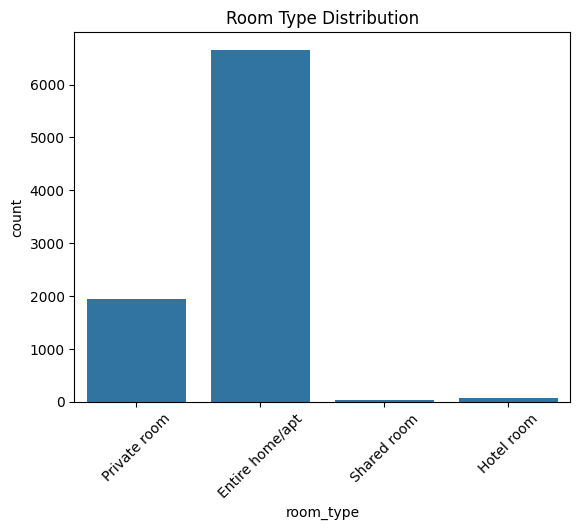

In [35]:
# Creates a count plot for room types.
sns.countplot(
    x='room_type',
    data=df
)
# Rotates X-axis labels by 45 degrees.
plt.xticks(rotation=45)

plt.title("Room Type Distribution")

plt.show()

In [36]:
top_neighborhoods = df[
    'neighbourhood'
].value_counts().head(10)
# Counts listings in each neighbourhood. - Selects the top 10 neighbourhoods.

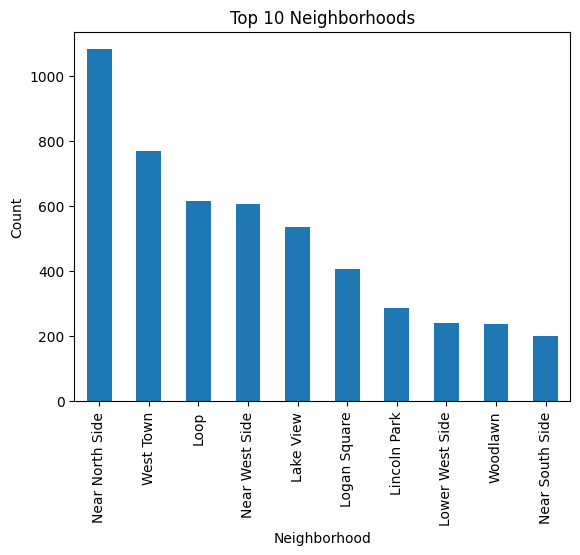

In [37]:
# # Identifies the top 10 neighbourhoods with the highest number of Airbnb listings and displays them using a bar chart.
top_neighborhoods.plot(kind='bar')

plt.title("Top 10 Neighborhoods")

plt.xlabel("Neighborhood")

plt.ylabel("Count")

plt.show()

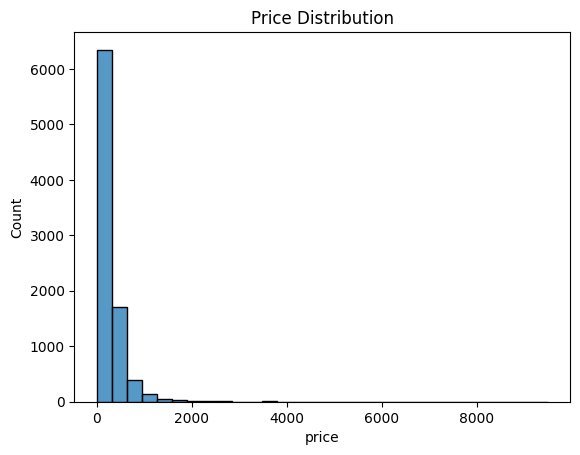

In [38]:
# # Creates a histogram to analyze the distribution of Airbnb listing prices.
sns.histplot(
    df['price'],
    bins=30
)

plt.title("Price Distribution")

plt.show()

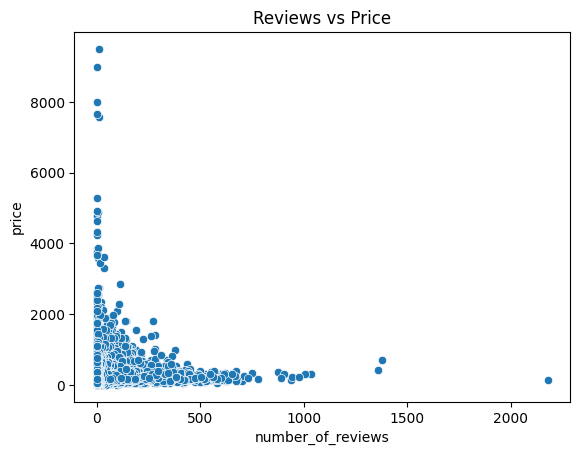

In [40]:
# # Creates a scatter plot to examine the relationship between the number of reviews and the listing price.
sns.scatterplot(
    x='number_of_reviews',
    y='price',
    data=df
)

plt.title("Reviews vs Price")

plt.show()

In [63]:
## Selects numeric columns and creates a correlation heatmap to understand the relationships between numerical features.
numeric_df = df.select_dtypes(include=np.number)

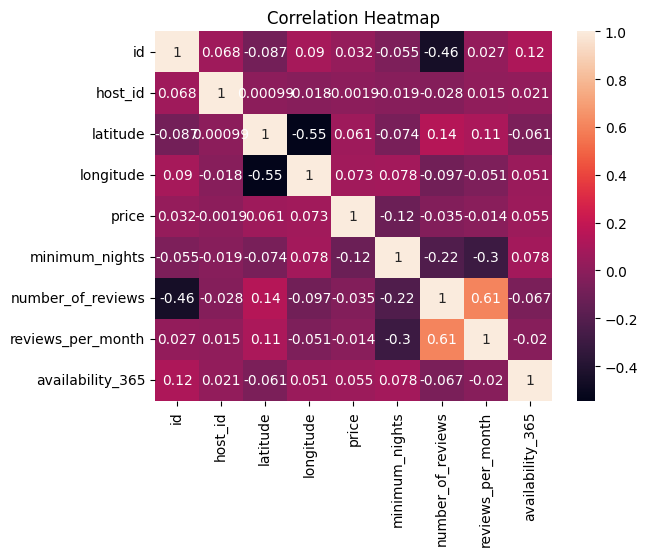

In [64]:
sns.heatmap(
    numeric_df.corr(),
    annot=True
)

plt.title("Correlation Heatmap")

plt.show()

## Data Transformation

Created additional categorical columns from existing numerical data to improve data visualization and analysis.


In [48]:
# Creates a new categorical column by grouping listing prices into Budget, Standard, and Luxury categories.
# Create Price Category
df['Price_Category'] = pd.cut(
    df['price'],
    bins=[0, 100, 250, float('inf')],
    labels=['Budget', 'Standard', 'Luxury']
)

# Display the new column
df[['price', 'Price_Category']].head()

,price,Price_Category
0,171.0,Standard
1,112.0,Standard
2,280.0,Luxury
3,422.0,Luxury
4,109.0,Standard


In [47]:
# Creates a new categorical column by grouping listings based on annual availability.

# Create Availability Category
df['Availability_Category'] = pd.cut(
    df['availability_365'],
    bins=[0, 120, 240, 365],
    labels=['Low', 'Medium', 'High']
)

# Display the new column
df[['availability_365', 'Availability_Category']].head()

,availability_365,Availability_Category
0,310,High
1,247,High
2,283,High
3,136,Medium
4,326,High


In [49]:
# Display the transformed columns
df[['price', 'Price_Category', 'availability_365', 'Availability_Category']].head(10)

,price,Price_Category,availability_365,Availability_Category
0,171.0,Standard,310,High
1,112.0,Standard,247,High
2,280.0,Luxury,283,High
3,422.0,Luxury,136,Medium
4,109.0,Standard,326,High
5,199.0,Standard,287,High
6,343.0,Luxury,357,High
7,434.0,Luxury,331,High
8,348.0,Luxury,289,High
9,72.0,Budget,338,High


In [65]:
# Saves the cleaned Airbnb dataset as a CSV file for further analysis and Power BI dashboard creation.
df.to_csv("clean_airbnb.csv", index=False)

In [66]:
# Check all column names
print(df.columns.tolist())

['id', 'name', 'host_id', 'host_name', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365']


In [67]:
from google.colab import files
files.download("clean_airbnb.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
# to check whether data is cleaned properly or not
df.head()


,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365,Price_Category,Availability_Category
0,2384,Hyde Park: 5 minute walk to Obama Presidential...,2613.0,Rebecca,Hyde Park,41.78790,-87.58780,Private room,171.0,2.0,268,1.92,310,Standard,High
1,7126,Tiny Studio Apartment 94 Walk Score,17928.0,Sarah,West Town,41.90166,-87.68021,Entire home/apt,112.0,2.0,626,3.03,247,Standard,High
2,10945,The Biddle House (#1),33004.0,Elizabeth,Lincoln Park,41.91196,-87.63981,Entire home/apt,280.0,4.0,152,1.03,283,Luxury,High
3,12140,Lincoln Park Guest House,46734.0,Shar And Robert,Lincoln Park,41.92357,-87.64947,Private room,422.0,2.0,21,0.16,136,Luxury,Medium
4,71930,"Rest, Relax and Explore",334241.0,Michael And Veronica,West Town,41.89615,-87.67934,Private room,109.0,3.0,158,0.86,326,Standard,High


## Power BI Dashboard

The cleaned dataset was imported into Power BI to create an interactive dashboard for analyzing Airbnb listings. The dashboard includes KPI cards, room type distribution, top neighbourhoods, price distribution, reviews vs price analysis, and interactive slicers.


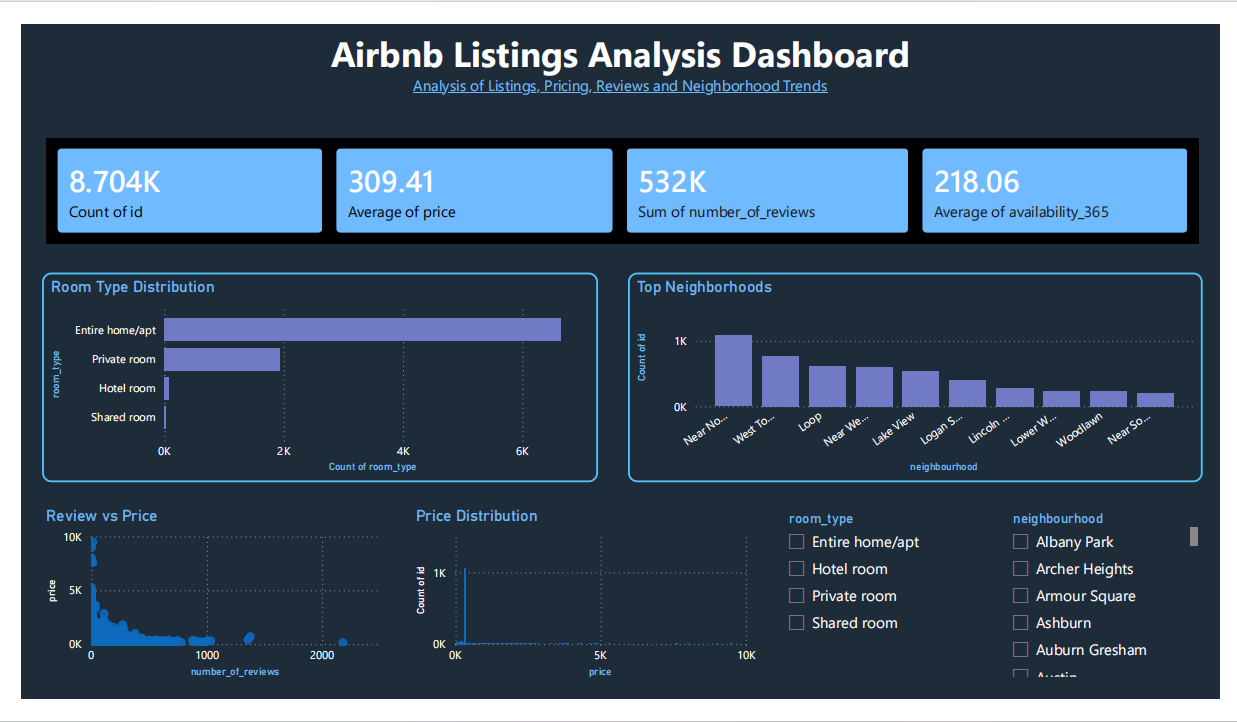


## Conclusion

This project successfully analyzed the Airbnb Listings dataset using Python and Power BI. The data was cleaned by handling missing values, removing duplicates, correcting data types, and preparing the dataset for analysis. Additional data transformation was performed by creating categorical columns such as Price Category and Availability Category to improve visualization.

Exploratory Data Analysis (EDA) was conducted to identify important patterns and trends in the dataset. The analysis highlighted the distribution of room types, the top neighbourhoods based on listings, price distribution, the relationship between price and reviews, and the correlation between numerical features.

Finally, an interactive Power BI dashboard was developed to present the key insights using KPI cards, charts, and slicers. The dashboard enables users to explore Airbnb listings efficiently and supports better understanding of pricing patterns, property distribution, and neighbourhood performance.

Overall, this project demonstrates the complete data analysis workflow, including data cleaning, data transformation, exploratory data analysis, and dashboard creation for effective decision-making.


# Thank You